### Unsupervised Deep Learning
#### Assignment 2
#### Image Generation using (β-)VAE, VQ-VAE with PixelCNN prior and WGAN / WGAN-GP
##### Part B: WGAN and WGAN-GP

##### Group 6

Students' details

|Name|BITS ID| Contribution %|
|---|---|---|
|Brincita Prima Cutinha | 2025AG05256 | 100 |
|Devang Ajay Kamble | 2025AE05173 | 100 |
|Saksham Jindal | 2025AE05983 | 100 |
|Shantanu Biswas | 2025AE05079 | 100 |
|Ashish Chauhan | 2025AG05928 | 100 |

#### Prerequisites

This notebook was developed and tested with the following environment.

**Python:** 3.10+

**Packages:**

| Package | Used for |
|---|---|
| `torch` / `torchvision` (CUDA build) | models, training, CIFAR-10 loader |
| `numpy` | array/numeric operations |
| `pandas` | results tables |
| `matplotlib` | plotting (curves, reconstructions, sample grids) |
| `scipy` | matrix square root inside the FID computation |
| `pytorch-fid` | pretrained Inception-v3 (pool3, 2048-d) used for FID, precision and recall |
| `pillow` | saving image grids |

Run the cell below once to install

In [1]:
# Uncomment the line below to install any missing packages in this environment.
# %pip install -q torch torchvision numpy pandas matplotlib scipy pytorch-fid pillow

import sys
import numpy
import pandas
import matplotlib
import scipy
import PIL
import torch
import torchvision
import pytorch_fid

print("Python      :", sys.version.split()[0])
print("numpy       :", numpy.__version__)
print("pandas      :", pandas.__version__)
print("matplotlib  :", matplotlib.__version__)
print("scipy       :", scipy.__version__)
print("pillow      :", PIL.__version__)
print("torch       :", torch.__version__)
print("torchvision :", torchvision.__version__)
print("pytorch-fid :", pytorch_fid.__version__)
print("CUDA        :", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

Python      : 3.10.11
numpy       : 2.2.6
pandas      : 2.3.3
matplotlib  : 3.10.9
scipy       : 1.15.3
pillow      : 12.3.0
torch       : 2.5.1+cu121
torchvision : 0.20.1+cu121
pytorch-fid : 0.3.0
CUDA        : True NVIDIA GeForce RTX 3080 Laptop GPU


### Part B: Wasserstein GAN (weight clipping) and WGAN-GP (gradient penalty)

#### Objective

Train two Wasserstein GANs on CIFAR-10 — the original **WGAN** (Lipschitz constraint enforced by *weight clipping*) and
**WGAN-GP** (Lipschitz constraint enforced by a *gradient penalty*) — generate random samples, and compute their FID.

A Wasserstein GAN replaces the JS-divergence of the vanilla GAN by the Earth-Mover distance. By Kantorovich-Rubinstein duality

`W(P_r, P_g) = sup_{||f||_L <= 1}  E_{x~P_r}[f(x)] - E_{x~P_g}[f(x)]`,

so the discriminator becomes a **critic** `f` (no sigmoid, no log) that must be 1-Lipschitz:

* **WGAN:** after every critic update the weights are clipped to `[-c, c]`, `c = 0.01`.
* **WGAN-GP:** the constraint is replaced by the penalty `λ · E_x̂ [ (||∇_x̂ f(x̂)||₂ − 1)² ]`, `λ = 10`, on random
  interpolates `x̂ = ε x_real + (1 − ε) x_fake`.

To isolate **the Lipschitz mechanism as the only difference**, both models use the *same* generator, the *same* critic
architecture (without any normalisation layer, which is also required for the per-sample gradient penalty) and the same
number of critic steps per generator step (`n_critic = 5`).

Expected Result

We expect to see:

* The critic loss `-(E[f(real)] - E[f(fake)])` is an estimate of the (negative) **Wasserstein distance**. Unlike the loss of a
  vanilla GAN it should **decrease in magnitude as training progresses and track sample quality**.
* **WGAN-GP clearly beats WGAN with weight clipping.** Clipping forces most weights onto the boundary `±c` and limits the
  capacity of the critic, which gives blurry, low-diversity samples and a high FID; the gradient penalty constrains
  the function rather than the parameters, so the critic stays expressive, training is stable and the FID is much lower
  (roughly 40-70 for a plain DCGAN-sized model, against 100 or more for clipping).
* The mean gradient norm of the WGAN-GP critic on interpolates should be driven towards **1** by the penalty.
* The FID of both GANs should fall steadily during training, and the final WGAN-GP FID should be well below that of
  the VAE of Part A-1 (and in the range of the VQ-VAE + PixelCNN of Part A-2).

#### Imports

In [2]:
# imports
import os
import json
import time
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from scipy import linalg

#### Configuration

In [3]:
# Global configuration
# Set UDL_SMOKE=1 in the environment for a 1-minute dry run of the whole notebook.
SMOKE = os.environ.get("UDL_SMOKE", "0") == "1"

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

RES_DIR = "results_smoke" if SMOKE else "results"
os.makedirs(RES_DIR, exist_ok=True)
os.makedirs(f"{RES_DIR}/samples", exist_ok=True)
os.makedirs(f"{RES_DIR}/figures", exist_ok=True)

N_TRAIN = 5000 if SMOKE else 50000      # number of training images used
N_FID = 1000 if SMOKE else 10000        # generated images per FID evaluation
FID_REPEATS = 1 if SMOKE else 3         # independent sampling rounds -> mean +- std

CFG = dict(
    latent_dim=128,
    batch_size=64,
    n_critic=5,                              # critic updates per generator update
    g_iters=60 if SMOKE else 25000,          # generator updates
    eval_every=30 if SMOKE else 2500,        # FID checkpoints during training
    quick_fid_n=1000 if SMOKE else 5000,     # images for the in-training FID checkpoints
    log_every=10 if SMOKE else 500,
    clip=0.01,                               # WGAN weight clipping
    gp_lambda=10.0,                          # WGAN-GP penalty weight
)
RESULTS_PATH = f"{RES_DIR}/partB_results.json"
if os.path.exists(RESULTS_PATH):
    os.remove(RESULTS_PATH)          # a fresh run always rebuilds the results file

def set_seed(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
torch.backends.cudnn.benchmark = True

print("Device :", DEVICE, "| smoke run:", SMOKE)
print("Config :", CFG)

Device : cuda | smoke run: False
Config : {'latent_dim': 128, 'batch_size': 64, 'n_critic': 5, 'g_iters': 25000, 'eval_every': 2500, 'quick_fid_n': 5000, 'log_every': 500, 'clip': 0.01, 'gp_lambda': 10.0}


#### Load the dataset & Normalize the data

CIFAR-10 (60,000 colour images, 32x32x3). Pixel values are normalised to `[0, 1]` as required.
The official split is kept (50,000 train / 10,000 test); the whole dataset is held on the GPU as a
tensor, which removes the data-loader overhead from every training loop.

> **Note on the dataset source.** The official download server (`https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz`)
> ran at ~25 kB/s on our GPU machine, so we fetched the same archive from a Hugging Face mirror
> (`huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python`) instead. We checked it was byte-identical to the
> official file: same size (170,498,071 bytes) and same MD5 `c58f30108f718f92721af3b95e74349a`, the checksum
> torchvision itself checks. The dataset, split and preprocessing are unchanged; only the download location differs.
> A copy is in the repo under `data/` (split into two parts under 100 MB; see `ENV_SETUP.md`).

In [4]:
# Load CIFAR-10 and normalise to [0, 1]
def load_cifar10(root="./data"):
    train = torchvision.datasets.CIFAR10(root=root, train=True, download=True)
    test = torchvision.datasets.CIFAR10(root=root, train=False, download=True)

    def to_tensor(arr):
        x = torch.from_numpy(arr).float() / 255.0          # normalise pixels to [0, 1]
        return x.permute(0, 3, 1, 2).contiguous()          # NHWC -> NCHW

    return to_tensor(train.data), to_tensor(test.data)

X_train, X_test = load_cifar10()
X_train = X_train[:N_TRAIN].to(DEVICE)
X_test = X_test.to(DEVICE)

print("train :", tuple(X_train.shape), "range [%.1f, %.1f]" % (X_train.min().item(), X_train.max().item()))
print("test  :", tuple(X_test.shape))
DATA_VAR = X_train.var().item()
print("pixel variance of the training set: %.4f" % DATA_VAR)

Files already downloaded and verified


Files already downloaded and verified


train : (50000, 3, 32, 32) range [0.0, 1.0]
test  : (10000, 3, 32, 32)
pixel variance of the training set: 0.0633


#### Helper Functions

Shared utilities: batching, PSNR, parameter counts and image-grid plotting/saving.

In [5]:
def batches(X, batch_size, shuffle=True):
    # yields mini-batches of a GPU tensor
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X) - (batch_size - 1 if shuffle else 0), batch_size):
        yield X[idx[i:i + batch_size]]


def psnr_per_image(x, x_hat):
    # PSNR (dB) of every image for data in [0, 1]:  10 log10( 1 / MSE )
    mse = ((x - x_hat) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return 10 * torch.log10(1.0 / mse)


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def to_grid(imgs, nrow=10, scale=1):
    # imgs: N x 3 x H x W tensor in [0, 1]  ->  H' x W' x 3 numpy array
    g = torchvision.utils.make_grid(imgs.detach().cpu().clamp(0, 1), nrow=nrow, padding=1, pad_value=1.0)
    g = g.permute(1, 2, 0).numpy()
    if scale > 1:
        g = np.kron(g, np.ones((scale, scale, 1)))
    return g


def show_grid(imgs, title="", nrow=10, scale=1, figsize=(7, 7), save=None):
    g = to_grid(imgs, nrow, scale)
    plt.figure(figsize=figsize)
    plt.imshow(g)
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    if save:
        plt.savefig(f"{RES_DIR}/figures/{save}.png", dpi=150, bbox_inches="tight")
    plt.show()


def save_100(imgs, name):
    # keep the 100 images used for the Part-C visual comparison (uint8 -> small files)
    arr = (imgs[:100].detach().cpu().clamp(0, 1).numpy() * 255).round().astype(np.uint8)
    np.save(f"{RES_DIR}/samples/{name}_100.npy", arr)


def update_results(path, key, value):
    # merge one entry into a results JSON file
    data = json.load(open(path)) if os.path.exists(path) else {}
    data[key] = value
    json.dump(data, open(path, "w"), indent=1)

#### Evaluation metrics: FID, Precision and Recall

**FID** (Frechet Inception Distance) compares the Gaussian statistics `(mu, Sigma)` of Inception-v3 pool3
features of real and generated images: `FID = ||mu_r - mu_g||^2 + Tr(S_r + S_g - 2 (S_r S_g)^(1/2))`.
Lower is better.

* **Reference statistics:** the CIFAR-10 *training* set.
* **Generated set:** `N_FID` = 10,000 images; every FID in this notebook is the mean +- std of
  `FID_REPEATS` independent sampling rounds, so a table entry also shows how noisy the metric is.
* **Inception weights:** the standard TF-FID port shipped with `pytorch-fid`, so the numbers are
  comparable with published CIFAR-10 FIDs.

As an extra we also report the k-NN **Precision / Recall** of Kynkaanniemi et al. (2019) on the same
features: precision = fraction of generated images that fall inside the real manifold (*fidelity*),
recall = fraction of real images covered by the generated manifold (*diversity*). FID alone cannot tell
"blurry but diverse" apart from "sharp but mode-collapsed"; these two numbers can.

In [6]:
from pytorch_fid.inception import InceptionV3
from pytorch_fid.fid_score import calculate_frechet_distance

inception = InceptionV3([InceptionV3.BLOCK_INDEX_BY_DIM[2048]]).to(DEVICE).eval()


@torch.no_grad()
def inception_features(x, batch_size=250):
    # x: N x 3 x H x W in [0, 1]  ->  N x 2048 float64 numpy features
    out = []
    for i in range(0, len(x), batch_size):
        f = inception(x[i:i + batch_size].to(DEVICE).float())[0]
        out.append(f.squeeze(-1).squeeze(-1).double().cpu())
    return torch.cat(out).numpy()


def gaussian_stats(feats):
    return feats.mean(0), np.cov(feats, rowvar=False)


def fid_from_feats(feats, ref_stats):
    mu, sigma = gaussian_stats(feats)
    return float(calculate_frechet_distance(mu, sigma, ref_stats[0], ref_stats[1]))


# ---- reference statistics (cached on disk) --------------------------------------------------
_ref_path = f"{RES_DIR}/cifar10_inception_ref.npz"
if os.path.exists(_ref_path):
    _z = np.load(_ref_path)
    REF_STATS, REAL_FEATS = (_z["mu"], _z["sigma"]), _z["real_feats"]
else:
    _train_feats = inception_features(X_train)
    REF_STATS = gaussian_stats(_train_feats)
    REAL_FEATS = inception_features(X_test)[:N_FID]            # real manifold for precision/recall
    np.savez(_ref_path, mu=REF_STATS[0], sigma=REF_STATS[1], real_feats=REAL_FEATS)

print("reference stats ready | real features for P/R:", REAL_FEATS.shape)
print("sanity: FID(test set vs train stats) = %.2f   (a perfect generator would sit near this value)"
      % fid_from_feats(inception_features(X_test), REF_STATS))


# ---- precision / recall -----------------------------------------------------------------------
def _kth_radius(X, k=3, bs=1000):
    r = []
    for i in range(0, len(X), bs):
        r.append(torch.cdist(X[i:i + bs], X).kthvalue(k + 1, dim=1).values)   # +1: the point itself
    return torch.cat(r)


def _covered(A, B, rB, bs=1000):
    hit = []
    for i in range(0, len(A), bs):
        hit.append((torch.cdist(A[i:i + bs], B) <= rB[None, :]).any(1))
    return torch.cat(hit).float().mean().item()


@torch.no_grad()
def precision_recall(fake_feats, real_feats=REAL_FEATS, k=3):
    R = torch.from_numpy(real_feats).float().to(DEVICE)
    G = torch.from_numpy(fake_feats).float().to(DEVICE)
    n = min(len(R), len(G))
    R, G = R[:n], G[:n]
    precision = _covered(G, R, _kth_radius(R, k))
    recall = _covered(R, G, _kth_radius(G, k))
    return precision, recall


def evaluate_generator(sample_fn, n=None, repeats=None):
    # sample_fn(n) must return an n x 3 x 32 x 32 tensor in [0, 1].
    # Returns FID mean/std over `repeats` rounds and P/R of the first round.
    n = n or N_FID
    repeats = repeats or FID_REPEATS
    fids, pr, first = [], None, None
    for r in range(repeats):
        set_seed(SEED + 1000 + r)
        imgs = sample_fn(n)
        feats = inception_features(imgs)
        fids.append(fid_from_feats(feats, REF_STATS))
        if r == 0:
            pr = precision_recall(feats)
            first = imgs[:100].detach().cpu()
    return {"FID": float(np.mean(fids)), "FID_std": float(np.std(fids)),
            "Precision": pr[0], "Recall": pr[1]}, first

reference stats ready | real features for P/R: (10000, 2048)


sanity: FID(test set vs train stats) = 3.15   (a perfect generator would sit near this value)


#### Architectures

* **Generator** (`z ∈ R^128 → 32x32x3`): linear → `4x4x256`, then three stride-2 transposed convolutions
  (`256→128→64→3`) with BatchNorm + ReLU, and a `tanh` output in `[-1, 1]`.
* **Critic** (`32x32x3 → R`): three stride-2 `4x4` convolutions (`3→64→128→256`) with LeakyReLU(0.2), then a linear
  layer to a **single unbounded score** (no sigmoid). No BatchNorm / LayerNorm anywhere in the critic.

The data are scaled from `[0, 1]` to `[-1, 1]` for training (matching the `tanh` generator output) and mapped back to
`[0, 1]` for every metric and picture.

In [7]:
class Generator(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(latent_dim, 4 * 4 * 256), nn.BatchNorm1d(4 * 4 * 256), nn.ReLU())
        self.net = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(),   # 8x8
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),     # 16x16
            nn.ConvTranspose2d(64, 3, 4, 2, 1), nn.Tanh(),                          # 32x32
        )
        self.latent_dim = latent_dim

    def forward(self, z):
        return self.net(self.fc(z).view(-1, 256, 4, 4))


class Critic(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1), nn.LeakyReLU(0.2),       # 16x16
            nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(0.2),     # 8x8
            nn.Conv2d(128, 256, 4, 2, 1), nn.LeakyReLU(0.2),    # 4x4
            nn.Flatten(), nn.Linear(256 * 16, 1),
        )

    def forward(self, x):
        return self.net(x).view(-1)


print("generator parameters:", count_params(Generator(CFG["latent_dim"])))
print("critic parameters   :", count_params(Critic()))

generator parameters: 1195587
critic parameters   : 662977


#### Training and evaluation helpers

* `gradient_penalty` implements `E[(||∇_x̂ f(x̂)||₂ − 1)²]` with `create_graph=True` so that the penalty itself can be
  differentiated with respect to the critic weights.
* `train_gan(mode, ...)` runs the alternating optimisation. In each iteration the critic is trained for `n_critic = 5`
  steps and the generator for one. Optimisers follow the original papers: **WGAN** uses RMSprop with `lr = 5e-5`
  (momentum-based optimisers were reported to be unstable with clipping); **WGAN-GP** uses Adam with `lr = 1e-4`,
  `β = (0.5, 0.9)`.
* The logged **Wasserstein estimate** is `E[f(real)] − E[f(fake)]`; for WGAN-GP we also log the mean critic-gradient norm
  on the interpolates, for WGAN the fraction of critic weights that sit on the clipping boundary.
* An FID checkpoint (with `quick_fid_n` images, so slightly pessimistic compared with the final 10,000-image FID) is taken every
  `eval_every` generator iterations to obtain the FID-versus-iteration curve.

In [8]:
def gradient_penalty(critic, real, fake):
    eps = torch.rand(real.size(0), 1, 1, 1, device=DEVICE)
    x_hat = (eps * real + (1 - eps) * fake).requires_grad_(True)
    grads = torch.autograd.grad(critic(x_hat).sum(), x_hat, create_graph=True)[0]
    norms = grads.flatten(1).norm(2, dim=1)
    return ((norms - 1) ** 2).mean(), norms.mean().item()


@torch.no_grad()
def sample_gan(G, n, bs=1000):
    G.eval()
    out = []
    for i in range(0, n, bs):
        z = torch.randn(min(bs, n - i), G.latent_dim, device=DEVICE)
        out.append((G(z) + 1) / 2)                      # [-1, 1] -> [0, 1]
    G.train()
    return torch.cat(out).clamp(0, 1)


def clip_saturation(critic, c):
    w = torch.cat([p.detach().flatten() for p in critic.parameters()])
    return (w.abs() >= 0.999 * c).float().mean().item()


def train_gan(mode, g_iters, seed=SEED):
    assert mode in ("wgan", "wgan_gp")
    set_seed(seed)
    G, D = Generator(CFG["latent_dim"]).to(DEVICE), Critic().to(DEVICE)
    if mode == "wgan":
        opt_d = torch.optim.RMSprop(D.parameters(), lr=5e-5)
        opt_g = torch.optim.RMSprop(G.parameters(), lr=5e-5)
    else:
        opt_d = torch.optim.Adam(D.parameters(), lr=1e-4, betas=(0.5, 0.9))
        opt_g = torch.optim.Adam(G.parameters(), lr=1e-4, betas=(0.5, 0.9))

    B, zdim, n = CFG["batch_size"], CFG["latent_dim"], len(X_train)
    hist = {"iter": [], "w_dist": [], "critic_loss": [], "gen_loss": [], "grad_norm": [], "clip_frac": [],
            "fid_iter": [], "fid": [], "time": []}
    acc = {"w": [], "d": [], "g": [], "gn": []}
    t0 = time.time()
    for it in range(1, g_iters + 1):
        # ---- critic: n_critic steps --------------------------------------------------------------
        for _ in range(CFG["n_critic"]):
            real = X_train[torch.randint(n, (B,), device=DEVICE)] * 2 - 1
            with torch.no_grad():
                fake = G(torch.randn(B, zdim, device=DEVICE))
            d_real, d_fake = D(real).mean(), D(fake).mean()
            loss_d = d_fake - d_real
            if mode == "wgan_gp":
                gp, gn = gradient_penalty(D, real, fake)
                loss_d = loss_d + CFG["gp_lambda"] * gp
                acc["gn"].append(gn)
            opt_d.zero_grad(set_to_none=True)
            loss_d.backward()
            opt_d.step()
            if mode == "wgan":
                for p in D.parameters():
                    p.data.clamp_(-CFG["clip"], CFG["clip"])        # weight clipping
            acc["w"].append((d_real - d_fake).item()); acc["d"].append(loss_d.item())
        # ---- generator: 1 step ---------------------------------------------------------------------
        loss_g = -D(G(torch.randn(B, zdim, device=DEVICE))).mean()
        opt_g.zero_grad(set_to_none=True)
        loss_g.backward()
        opt_g.step()
        acc["g"].append(loss_g.item())

        if it % CFG["log_every"] == 0:
            hist["iter"].append(it)
            hist["w_dist"].append(float(np.mean(acc["w"]))); hist["critic_loss"].append(float(np.mean(acc["d"])))
            hist["gen_loss"].append(float(np.mean(acc["g"])))
            hist["grad_norm"].append(float(np.mean(acc["gn"])) if acc["gn"] else float("nan"))
            hist["clip_frac"].append(clip_saturation(D, CFG["clip"]) if mode == "wgan" else float("nan"))
            hist["time"].append(time.time() - t0)
            acc = {"w": [], "d": [], "g": [], "gn": []}
        if it % CFG["eval_every"] == 0 or it == g_iters:
            torch.cuda.synchronize()
            t_eval = time.time()
            f = fid_from_feats(inception_features(sample_gan(G, CFG["quick_fid_n"])), REF_STATS)
            hist["fid_iter"].append(it); hist["fid"].append(f)
            t0 += time.time() - t_eval                             # do not count evaluation time as training time
            print(f"{mode:>7} | iter {it:>6}/{g_iters} | W-dist estimate {hist['w_dist'][-1]:8.4f} | "
                  f"grad-norm {hist['grad_norm'][-1]:6.3f} | FID({CFG['quick_fid_n']}) {f:7.2f} | "
                  f"{time.time() - t0:6.0f} s")
    return G, D, hist, time.time() - t0

#### Train WGAN (weight clipping)

In [9]:
G_wgan, D_wgan, hist_wgan, time_wgan = train_gan("wgan", CFG["g_iters"])
print(f"\nWGAN trained in {time_wgan:.0f} s")

   wgan | iter   2500/25000 | W-dist estimate   2.3824 | grad-norm    nan | FID(5000)  227.05 |    144 s


   wgan | iter   5000/25000 | W-dist estimate   1.4077 | grad-norm    nan | FID(5000)  175.08 |    287 s


   wgan | iter   7500/25000 | W-dist estimate   0.9174 | grad-norm    nan | FID(5000)  150.64 |    430 s


   wgan | iter  10000/25000 | W-dist estimate   0.6365 | grad-norm    nan | FID(5000)  137.89 |    581 s


   wgan | iter  12500/25000 | W-dist estimate   0.4416 | grad-norm    nan | FID(5000)  128.90 |    708 s


   wgan | iter  15000/25000 | W-dist estimate   0.4189 | grad-norm    nan | FID(5000)  123.48 |    831 s


   wgan | iter  17500/25000 | W-dist estimate   0.5323 | grad-norm    nan | FID(5000)  128.98 |    951 s


   wgan | iter  20000/25000 | W-dist estimate   0.3554 | grad-norm    nan | FID(5000)  117.97 |   1059 s


   wgan | iter  22500/25000 | W-dist estimate   0.2937 | grad-norm    nan | FID(5000)  114.36 |   1153 s


   wgan | iter  25000/25000 | W-dist estimate   0.2570 | grad-norm    nan | FID(5000)  112.29 |   1251 s

WGAN trained in 1251 s


#### Train WGAN-GP (gradient penalty)

In [10]:
G_gp, D_gp, hist_gp, time_gp = train_gan("wgan_gp", CFG["g_iters"])
print(f"\nWGAN-GP trained in {time_gp:.0f} s")

wgan_gp | iter   2500/25000 | W-dist estimate   4.1409 | grad-norm  1.170 | FID(5000)  159.80 |    154 s


wgan_gp | iter   5000/25000 | W-dist estimate   3.7775 | grad-norm  1.156 | FID(5000)  145.98 |    313 s


wgan_gp | iter   7500/25000 | W-dist estimate   3.2721 | grad-norm  1.139 | FID(5000)  116.71 |    468 s


wgan_gp | iter  10000/25000 | W-dist estimate   2.9778 | grad-norm  1.127 | FID(5000)  102.69 |    628 s


wgan_gp | iter  12500/25000 | W-dist estimate   2.6965 | grad-norm  1.116 | FID(5000)   89.63 |    834 s


wgan_gp | iter  15000/25000 | W-dist estimate   2.5207 | grad-norm  1.110 | FID(5000)   85.01 |   1012 s


wgan_gp | iter  17500/25000 | W-dist estimate   2.3854 | grad-norm  1.105 | FID(5000)   76.11 |   1191 s


wgan_gp | iter  20000/25000 | W-dist estimate   2.2476 | grad-norm  1.100 | FID(5000)   74.72 |   1378 s


wgan_gp | iter  22500/25000 | W-dist estimate   2.1378 | grad-norm  1.095 | FID(5000)   72.55 |   1583 s


wgan_gp | iter  25000/25000 | W-dist estimate   2.0564 | grad-norm  1.092 | FID(5000)   66.23 |   1774 s

WGAN-GP trained in 1774 s


#### Training dynamics: Wasserstein estimate, FID and Lipschitz diagnostics

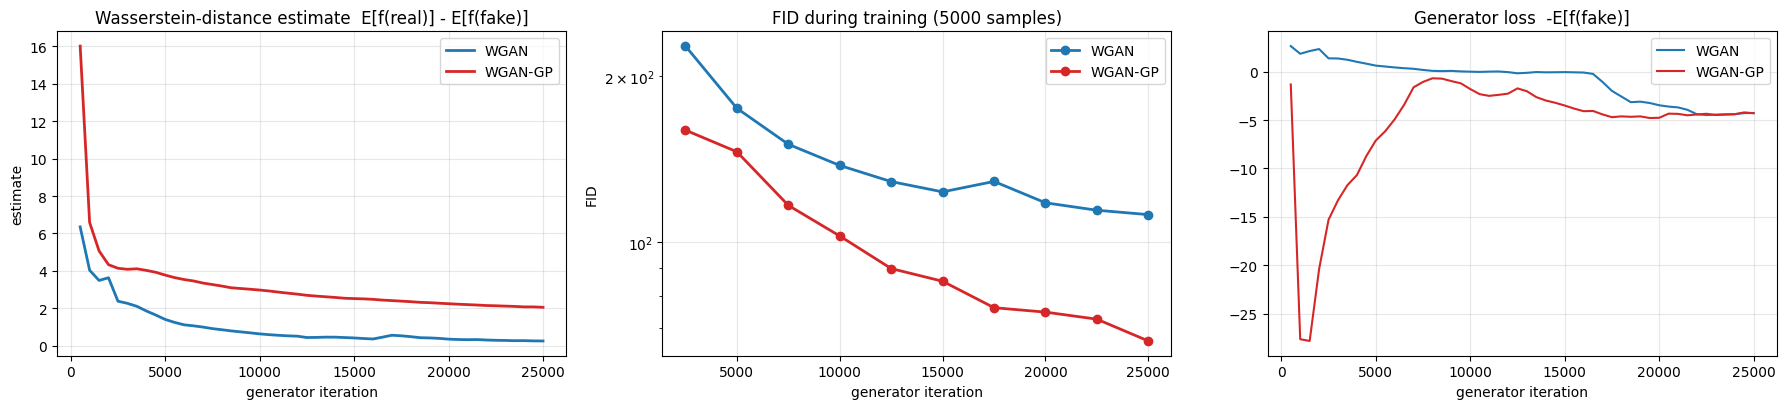

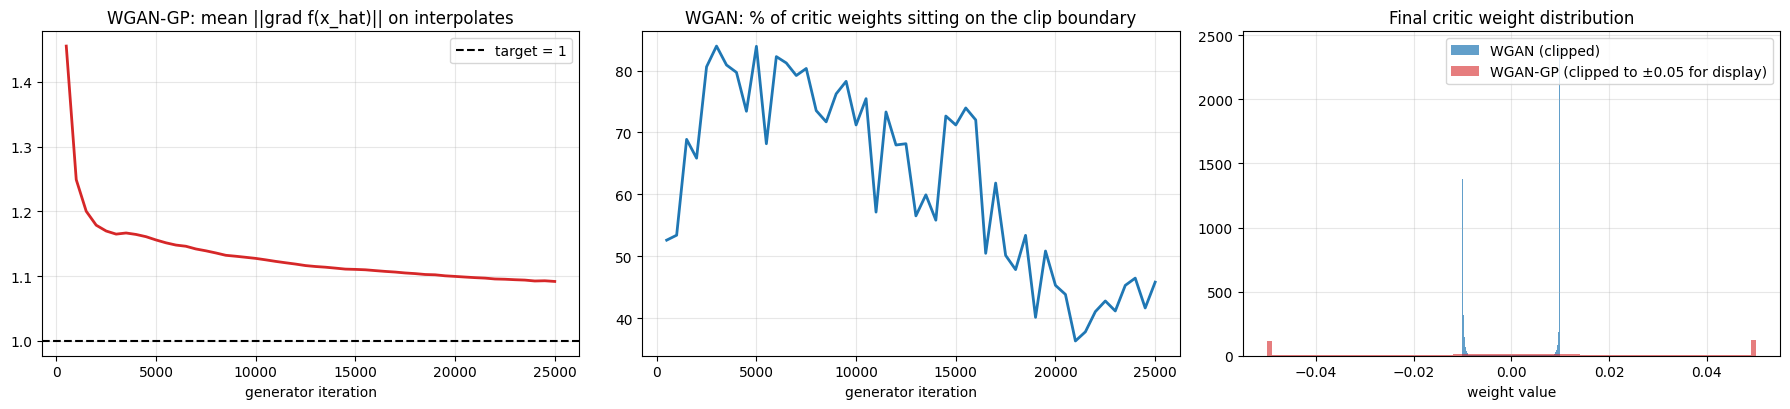

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
for h, name, c in [(hist_wgan, "WGAN", "C0"), (hist_gp, "WGAN-GP", "C3")]:
    ax[0].plot(h["iter"], h["w_dist"], lw=2, label=name, color=c)
    ax[1].plot(h["fid_iter"], h["fid"], "o-", lw=2, label=name, color=c)
    ax[2].plot(h["iter"], h["gen_loss"], lw=1.5, label=name, color=c)
ax[0].set_title("Wasserstein-distance estimate  E[f(real)] - E[f(fake)]"); ax[0].set_ylabel("estimate")
ax[1].set_title(f"FID during training ({CFG['quick_fid_n']} samples)"); ax[1].set_ylabel("FID"); ax[1].set_yscale("log")
ax[2].set_title("Generator loss  -E[f(fake)]")
for a in ax:
    a.set_xlabel("generator iteration"); a.grid(alpha=0.3); a.legend()
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/gan_training_dynamics.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
ax[0].plot(hist_gp["iter"], hist_gp["grad_norm"], lw=2, color="C3"); ax[0].axhline(1, color="k", ls="--", label="target = 1")
ax[0].set_title("WGAN-GP: mean ||grad f(x_hat)|| on interpolates"); ax[0].set_xlabel("generator iteration"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(hist_wgan["iter"], 100 * np.array(hist_wgan["clip_frac"]), lw=2, color="C0")
ax[1].set_title("WGAN: % of critic weights sitting on the clip boundary"); ax[1].set_xlabel("generator iteration"); ax[1].grid(alpha=0.3)
w_clip = torch.cat([p.detach().flatten() for p in D_wgan.parameters()]).cpu().numpy()
w_gp = torch.cat([p.detach().flatten() for p in D_gp.parameters()]).cpu().numpy()
ax[2].hist(w_clip, bins=100, alpha=0.7, label="WGAN (clipped)", color="C0", density=True)
ax[2].hist(np.clip(w_gp, -0.05, 0.05), bins=100, alpha=0.6, label="WGAN-GP (clipped to ±0.05 for display)", color="C3", density=True)
ax[2].set_title("Final critic weight distribution"); ax[2].set_xlabel("weight value"); ax[2].legend(); ax[2].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/gan_lipschitz_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

#### Generate random samples and compute FID

Final evaluation uses `N_FID = 10,000` generated images per round and the mean +- std over independent rounds, exactly
like the VAE / VQ-VAE evaluation of Part A, so the numbers are directly comparable.

In [12]:
gan_rows, gan_samples = [], {}
for name, G, h, t_train in [("WGAN", G_wgan, hist_wgan, time_wgan), ("WGAN-GP", G_gp, hist_gp, time_gp)]:
    metrics, first = evaluate_generator(lambda n, G=G: sample_gan(G, n))
    gan_samples[name] = first
    torch.cuda.synchronize(); t0 = time.time(); sample_gan(G, 1000); torch.cuda.synchronize(); t_s = time.time() - t0
    row = {"Model": name, "FID": metrics["FID"], "FID std": metrics["FID_std"],
           "Precision": metrics["Precision"], "Recall": metrics["Recall"],
           "Best FID during training": min(h["fid"]),
           "Train time (s)": t_train, "Sec / generator iter": t_train / CFG["g_iters"],
           "Sampling (ms / 1000 img)": 1000 * t_s, "Params (G)": count_params(G), "Params (critic)": count_params(Critic())}
    gan_rows.append(row)
    update_results(RESULTS_PATH, name.lower().replace("-", "_"), {**row, "history": h})
    save_100(first, name.lower().replace("-", "_"))
    print(f"{name:>8} | FID {metrics['FID']:.2f} +- {metrics['FID_std']:.2f} | "
          f"precision {metrics['Precision']:.3f} | recall {metrics['Recall']:.3f}")

gan_table = pd.DataFrame(gan_rows).set_index("Model")
gan_table.round(3)

    WGAN | FID 110.34 +- 0.36 | precision 0.663 | recall 0.002


 WGAN-GP | FID 64.19 +- 0.23 | precision 0.580 | recall 0.137


,FID,FID std,Precision,Recall,Best FID during training,Train time (s),Sec / generator iter,Sampling (ms / 1000 img),Params (G),Params (critic)
Model,,,,,,,,,,
WGAN,110.340,0.356,0.663,0.002,112.289,1250.526,0.050,54.096,1195587,662977
WGAN-GP,64.188,0.231,0.580,0.137,66.234,1773.694,0.071,104.249,1195587,662977


#### Visual comparison of random samples

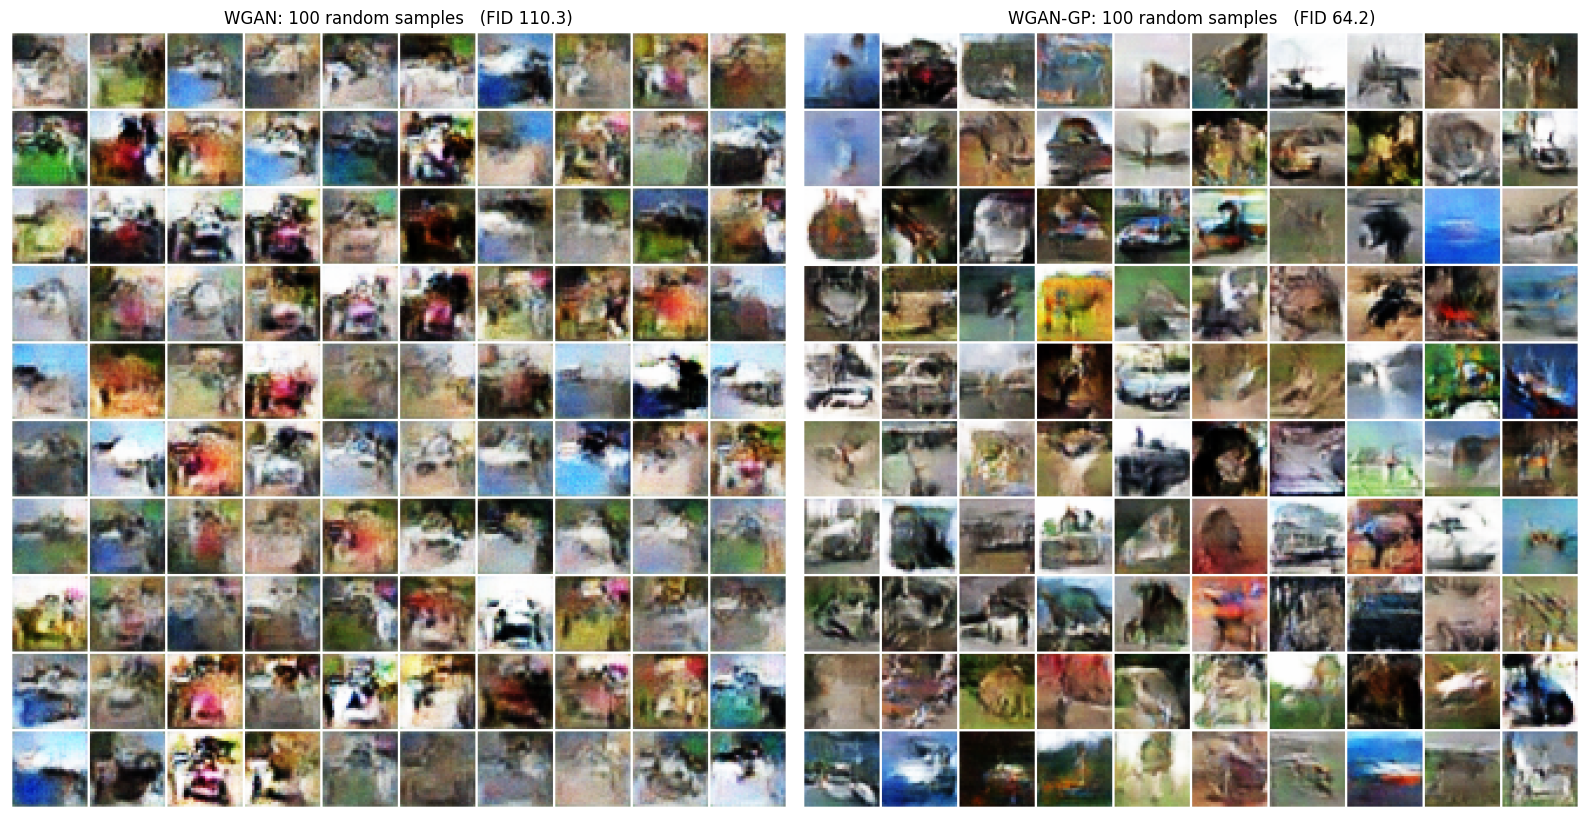

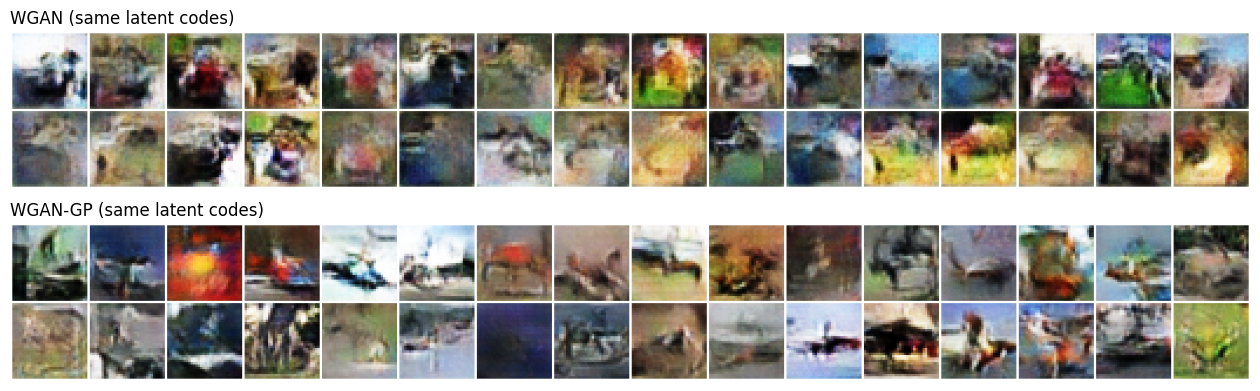

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8.2))
for a, name in zip(ax, ["WGAN", "WGAN-GP"]):
    a.imshow(to_grid(gan_samples[name], nrow=10, scale=3)); a.axis("off")
    a.set_title(f"{name}: 100 random samples   (FID {gan_table.loc[name, 'FID']:.1f})")
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/gan_100_samples.png", dpi=150, bbox_inches="tight")
plt.show()

# evolution of the samples is not stored, so show a fixed-noise comparison of the two final generators
set_seed(7)
z = torch.randn(32, CFG["latent_dim"], device=DEVICE)
with torch.no_grad():
    G_wgan.eval(); G_gp.eval()
    pair = [(G_wgan(z) + 1) / 2, (G_gp(z) + 1) / 2]
    G_wgan.train(); G_gp.train()
fig, ax = plt.subplots(2, 1, figsize=(14, 4))
for a, imgs, t in zip(ax, pair, ["WGAN (same latent codes)", "WGAN-GP (same latent codes)"]):
    a.imshow(to_grid(imgs, nrow=16, scale=2)); a.axis("off"); a.set_title(t, loc="left")
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/gan_same_noise.png", dpi=150, bbox_inches="tight")
plt.show()

#### Extra: latent-space interpolation

A generator that has learnt a smooth image manifold (and has not simply memorised the training set) produces
gradual, coherent transitions between two random latent codes.

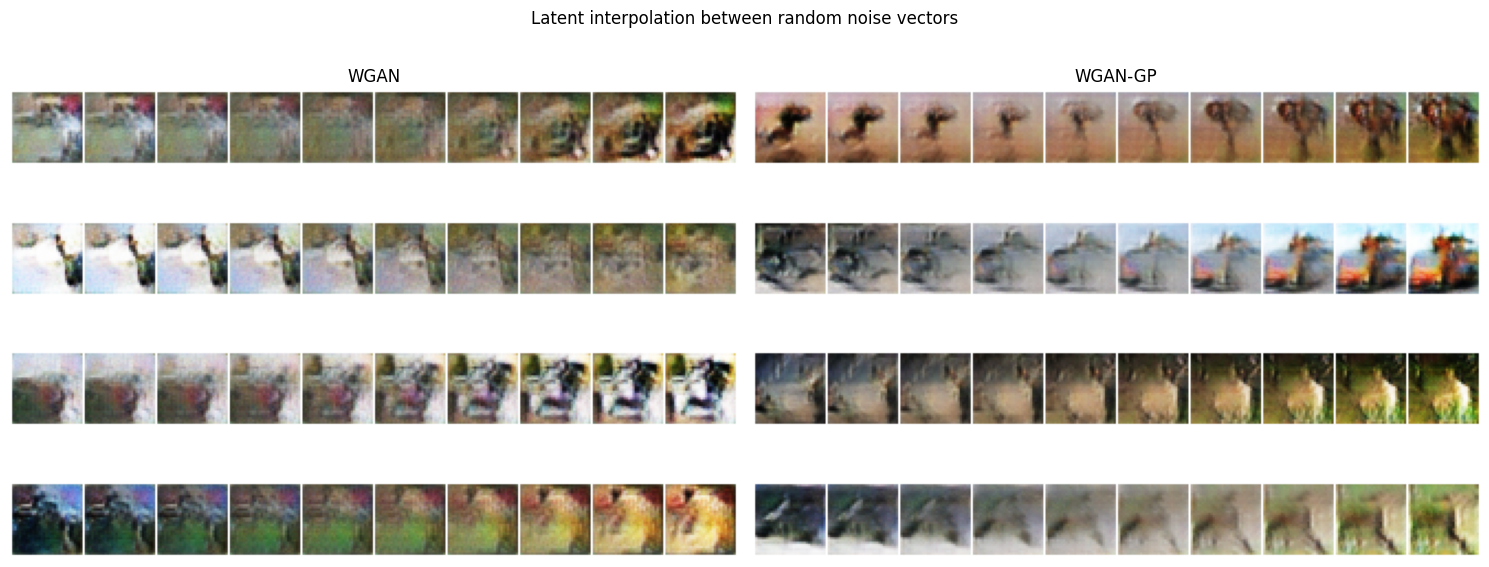

In [14]:
@torch.no_grad()
def gan_interpolate(G, z1, z2, steps=10):
    G.eval()
    a = torch.linspace(0, 1, steps, device=DEVICE)[:, None]
    out = (G((1 - a) * z1 + a * z2) + 1) / 2
    G.train()
    return out

set_seed(11)
zs = torch.randn(8, CFG["latent_dim"], device=DEVICE)
fig, axes = plt.subplots(4, 2, figsize=(15, 6.2))
for c, (name, G) in enumerate([("WGAN", G_wgan), ("WGAN-GP", G_gp)]):
    for r in range(4):
        axes[r, c].imshow(to_grid(gan_interpolate(G, zs[2 * r], zs[2 * r + 1]), nrow=10)); axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(name)
plt.suptitle("Latent interpolation between random noise vectors")
plt.tight_layout()
plt.savefig(f"{RES_DIR}/figures/gan_interpolation.png", dpi=150, bbox_inches="tight")
plt.show()

#### Analysis: WGAN vs WGAN-GP

Both models use the same generator, the same critic architecture (no normalisation), `n_critic = 5`, batch size 64, and 25,000 generator
iterations; **the way the Lipschitz constraint is enforced is the only difference** (weight clipping, RMSprop *vs.* gradient penalty, Adam).

| Model | FID (10k samples) | Best FID during training (5k samples) | Precision | Recall | Train time | s / generator iter |
|---|---|---|---|---|---|---|
| WGAN | 110.3 ± 0.4 | 112.3 | 0.663 | 0.002 | 20.8 min | 0.050 |
| WGAN-GP | **64.2 ± 0.2** | 66.2 | 0.580 | 0.137 | 29.6 min | 0.071 |

(The in-training FIDs use only 5,000 samples and are therefore biased upwards by about 2 points compared with the final 10,000-sample FID.)

---

##### (i) Sample quality: WGAN-GP is clearly better

**WGAN-GP's FID is 46 points (42 %) lower** than that of WGAN, a difference more than a hundred times the sampling noise
(± 0.2-0.4). The FID-versus-iteration curves are separated at every checkpoint (e.g. 160 *vs.* 227 after 2,500 iterations and 66 *vs.* 112 at the end).
WGAN-GP's curve is smooth and still falling at iteration 25,000, so it has **not converged**; WGAN's curve flattens and is
visibly noisy (it goes *up* from 123 to 129 between iterations 15,000 and 17,500).

The pictures agree. WGAN produces saturated, high-contrast colour patches with a plausible sky/ground layout but almost no
object structure. WGAN-GP's samples have recognisable vehicles, animals and scenes with consistent shading and sharper edges, although many
are still distorted, as expected from a small DCGAN-size model trained for 25k iterations. In the latent interpolations both generators change
smoothly (no jumps, so neither memorises the training set), but the WGAN-GP intermediates keep a coherent object throughout, while the WGAN ones
look like drifting colour fields.

##### (ii) Why: the way the Lipschitz constraint is enforced

* **Weight clipping starves the critic.** At the end 46 % of WGAN's critic weights sit exactly on the boundary `±0.01`, and the figure shows
  that the fraction stayed between about 36 % and 84 % during the whole run (peaking at about 84 % after 3,000-5,000 iterations). The weights
  are pushed into a **binary-like distribution** (two spikes at `±c`), so the critic uses only a fraction of its capacity and delivers
  poor gradients to the generator. The Wasserstein estimate of WGAN is therefore very small (0.26 at the end), because the clipped critic
  can only realise a loose lower bound of the true distance.
* **The gradient penalty constrains the function, not the parameters.** The critic gradient norm on the interpolates falls from about 1.46
  at the start to **1.09** at the end, i.e. close to the target of 1 (the penalty is soft and two-sided, so a small residual above 1 is
  expected), while its weights remain unconstrained — a considerable fraction lies far outside the `±0.01` box (see the weight histogram). The critic stays
  expressive, and its Wasserstein estimate (2.06) is about eight times larger than that of WGAN.
* The Wasserstein estimates of the two models are **not comparable in absolute value** (they are measured with different Lipschitz
  constraints); what matters is that each falls steadily while sample quality improves, which is the property that makes the WGAN
  loss useful as a training monitor, unlike the loss of a vanilla GAN. The generator loss of WGAN-GP shows an initial transient
  (it falls to about -28 in the first 1,500 iterations and then recovers) before it settles together with that of WGAN.

##### (iii) Precision and recall: read with care

WGAN-GP has the **much higher recall (0.137 *vs.* 0.002)**, i.e. it covers a far larger part of the real-image manifold; WGAN's
recall is practically zero, which says that its samples occupy only a narrow region and are far less diverse. WGAN's *precision* (0.66)
is nevertheless higher than that of WGAN-GP (0.58), which contradicts the visual impression and the FID. This is a known weakness of the k-NN
precision estimate: when the generated set is concentrated in a dense region of the real feature space, most of its points fall inside
real k-NN balls even if the images look poor. We therefore base the quality ranking on FID, recall and the pictures, and do not
interpret the precision of WGAN as better fidelity.

##### (iv) Cost

WGAN-GP needs one additional (double) back-propagation per critic step, so an iteration takes **1.4x as long** (0.071 s *vs.* 0.050 s), which gives
29.6 *vs.* 20.8 minutes for the 25k iterations. This is a small price for a 42 % lower FID. Sampling uses the identical generator, so the sampling times in the table
(54 and 104 ms per 1,000 images) only differ by measurement noise.

**Summary:** both models behave as the WGAN literature describes: the loss is a meaningful training signal, **WGAN-GP is more stable, much
more diverse and gives a far lower FID than weight clipping at an extra cost of 40 % per iteration**, and the improvement comes
entirely from the less restrictive way of enforcing 1-Lipschitzness. In terms of FID the final ranking over all of Part A and Part B is
**WGAN-GP (64.2) < VQ-VAE + PixelCNN (78-80) < WGAN (110.3) < β-VAE (141.5 for β = 1)**; Part C discusses this in detail.

#### Verification Screenshots

Screenshots of performing the notebook on BITS Infra (Prayogshala) are submitted separately as `.jpg` files.